# Schritt 3: EDP/NDP Random Graphs

Dieses reine Auswertungsnotebook fasst alle Experimente auf synthetischen Random Graphs zusammen. Es liest die frühen Random-Regular-Pilotreihen, die paper-nahen Pilot5-Reihen und die vollständigen 1000-Run-Reihen.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_step3_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        root = candidate / "schritt3_knoten_disjunkte_pfade"
        if root.exists():
            return root
        if candidate.name == "schritt3_knoten_disjunkte_pfade":
            return candidate
    raise FileNotFoundError("schritt3_knoten_disjunkte_pfade wurde nicht gefunden")


STEP3_ROOT = find_step3_root()
SRC_ROOT = STEP3_ROOT / "src"
COLORS = {"EDP": "#4C78A8", "NDP": "#F58518"}
MARKERS = {"EDP": "o", "NDP": "s"}
PLOT_ROOT = STEP3_ROOT / "evaluation" / "output" / "ndp_edp_random_runs1000"
PLOT_ROOT.mkdir(parents=True, exist_ok=True)

RANDOM_GRAPHS = [
    {"key": "n25_p015", "title": "Random (n=25, p=0.15)", "nodes": 25, "p": 0.15, "runs_files": 22},
    {"key": "n50_p015", "title": "Random (n=50, p=0.15)", "nodes": 50, "p": 0.15, "runs_files": 42},
    {"key": "n100_p002", "title": "Random (n=100, p=0.02)", "nodes": 100, "p": 0.02, "runs_files": 124},
]
print("Gemeinsamer Plot-Ordner:", PLOT_ROOT)


Gemeinsamer Plot-Ordner: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000


## Frühe Random-Regular-Pilotreihen



In [2]:
regular_configs = [
    {
        "model": "random",
        "directory": "output_ndp_edp_random_failures_series",
        "pattern": "ndp_edp_*_ff*.csv",
        "expected_files": 10,
        "expected_rows": 100,
    },
    {
        "model": "clustered",
        "directory": "output_ndp_edp_clustered_failures_series",
        "pattern": "ndp_edp_clustered_*_fs*_fd*.csv",
        "expected_files": 8,
        "expected_rows": 100,
    },
]

regular_frames = []
for config in regular_configs:
    input_dir = SRC_ROOT / config["directory"]
    csv_files = sorted(input_dir.glob(config["pattern"]))
    assert len(csv_files) == config["expected_files"]
    for csv_path in csv_files:
        frame = pd.read_csv(csv_path)
        assert len(frame) == config["expected_rows"]
        assert frame["rep"].nunique() == config["expected_rows"]
        assert (frame["nrEDPs"] >= frame["nrNDPs"]).all()
        frame["seriesModel"] = config["model"]
        regular_frames.append(frame)

regular_raw = pd.concat(regular_frames, ignore_index=True)
display(regular_raw.groupby(["seriesModel", "failureType"]).size().unstack(fill_value=0))


failureType,link,node
seriesModel,,
clustered,400,400
random,500,500


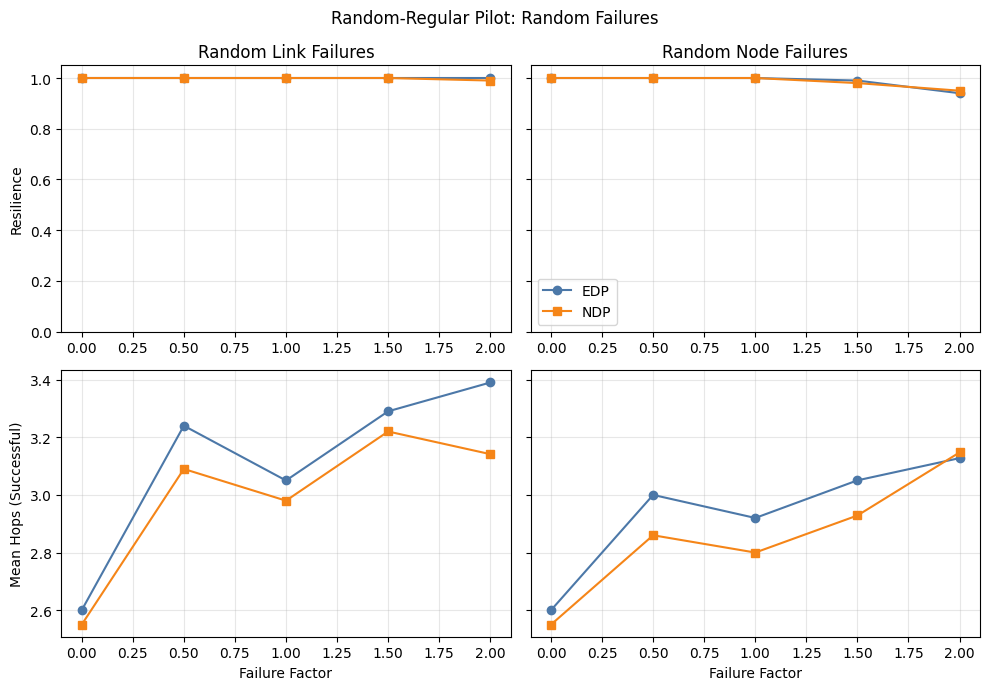

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_regular_pilot_random.png


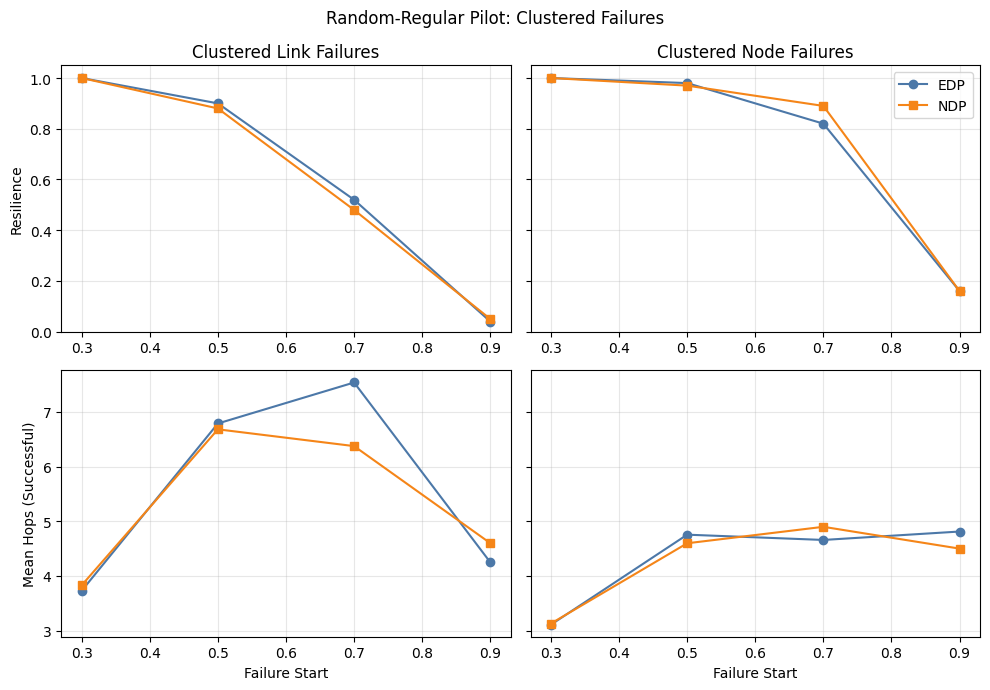

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_regular_pilot_clustered.png


,failureModel,failureType,xValue,algorithm,meanFailures,resilience
0,clustered,link,0.3,EDP,1.00,1.00
1,clustered,link,0.3,NDP,1.00,1.00
2,clustered,link,0.5,EDP,4.48,0.90
3,clustered,link,0.5,NDP,4.48,0.88
4,clustered,link,0.7,EDP,9.32,0.52
5,clustered,link,0.7,NDP,9.32,0.48
6,clustered,link,0.9,EDP,17.83,0.04
7,clustered,link,0.9,NDP,17.83,0.05
8,clustered,node,0.3,EDP,1.00,1.00
9,clustered,node,0.3,NDP,1.00,1.00


In [3]:
def summarize(frame, graph_column=None):
    group_columns = ["failureModel", "failureType", "failFactor", "failureStart"]
    if graph_column:
        group_columns.insert(0, graph_column)
    rows = []
    for keys, group in frame.groupby(group_columns, dropna=False):
        keys = keys if isinstance(keys, tuple) else (keys,)
        values = dict(zip(group_columns, keys))
        x_value = values["failFactor"] if values["failureModel"] == "random" else values["failureStart"]
        for algorithm in ["EDP", "NDP"]:
            hops = group[f"hops{algorithm}"]
            successful = group[hops != -1]
            row = {
                **values,
                "xValue": x_value,
                "algorithm": algorithm,
                "resilience": (hops != -1).mean(),
                "meanHopsSuccessful": successful[f"hops{algorithm}"].mean(),
                "meanFailures": group["nrFails"].mean(),
            }
            rows.append(row)
    return pd.DataFrame(rows)


regular_summary = summarize(regular_raw)


def plot_regular_pilot(model):
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey="row")
    x_label = "Failure Factor" if model == "random" else "Failure Start"
    for column, failure_type in enumerate(["link", "node"]):
        subset = regular_summary[
            (regular_summary["failureModel"] == model)
            & (regular_summary["failureType"] == failure_type)
        ]
        for algorithm in ["EDP", "NDP"]:
            line = subset[subset["algorithm"] == algorithm]
            axes[0, column].plot(line["xValue"], line["resilience"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm)
            axes[1, column].plot(line["xValue"], line["meanHopsSuccessful"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm)
        axes[0, column].set_title(f"{model.title()} {failure_type.title()} Failures")
        axes[0, column].set_ylim(0, 1.05)
        axes[0, column].grid(alpha=0.3)
        axes[1, column].grid(alpha=0.3)
        axes[1, column].set_xlabel(x_label)
    axes[0, 0].set_ylabel("Resilience")
    axes[1, 0].set_ylabel("Mean Hops (Successful)")
    axes[0, 1].legend()
    fig.suptitle(f"Random-Regular Pilot: {model.title()} Failures")
    plt.tight_layout()
    output_path = PLOT_ROOT / f"ndp_edp_random_regular_pilot_{model}.png"
    plt.savefig(output_path, dpi=180)
    plt.show()
    print("Plot:", output_path)


for model in ["random", "clustered"]:
    plot_regular_pilot(model)

display(
    regular_summary[
        ["failureModel", "failureType", "xValue", "algorithm", "meanFailures", "resilience"]
    ]
)


## Paper-nahe Random-Graph-Reihen

In Anlehnung an das Paper werden die Erdos-Renyi-Graphen in Titeln und Plots als Random Graphs bezeichnet. Pilot5 und 1000 Runs werden gemeinsam ausgewertet, bleiben aber als getrennte Reihen sichtbar.

In [4]:
def load_random_series(series):
    frames = []
    expected_rows = 5 if series == "pilot5" else 1000
    for graph in RANDOM_GRAPHS:
        for model in ["random", "clustered"]:
            input_dir = SRC_ROOT / f"output_ndp_edp_er_{model}_{graph['key']}_{series}"
            csv_files = sorted(input_dir.glob("*.csv"))
            expected_files = 8 if series == "pilot5" else (graph["runs_files"] if model == "random" else 14)
            assert len(csv_files) == expected_files, (
                f"{input_dir}: erwartet {expected_files} CSVs, gefunden {len(csv_files)}"
            )
            for csv_path in csv_files:
                frame = pd.read_csv(csv_path)
                assert len(frame) == expected_rows
                assert frame["rep"].nunique() == expected_rows
                assert set(frame["graphType"]) == {"erdos_renyi"}
                assert set(frame["nrNodes"]) == {graph["nodes"]}
                assert frame["edgeProb"].sub(graph["p"]).abs().max() < 1e-12
                frame["graphKey"] = graph["key"]
                frame["series"] = series
                frames.append(frame)
    return pd.concat(frames, ignore_index=True)


paper_raw = pd.concat(
    [load_random_series("pilot5"), load_random_series("runs1000")],
    ignore_index=True,
)
display(paper_raw.groupby(["series", "graphKey", "failureModel", "failureType"]).size().unstack(fill_value=0))


failureType                       link   node
series   graphKey  failureModel              
pilot5   n100_p002 clustered        20     20
                   random           20     20
         n25_p015  clustered        20     20
                   random           20     20
         n50_p015  clustered        20     20
                   random           20     20
runs1000 n100_p002 clustered      7000   7000
                   random        62000  62000
         n25_p015  clustered      7000   7000
                   random        11000  11000
         n50_p015  clustered      7000   7000
                   random        21000  21000

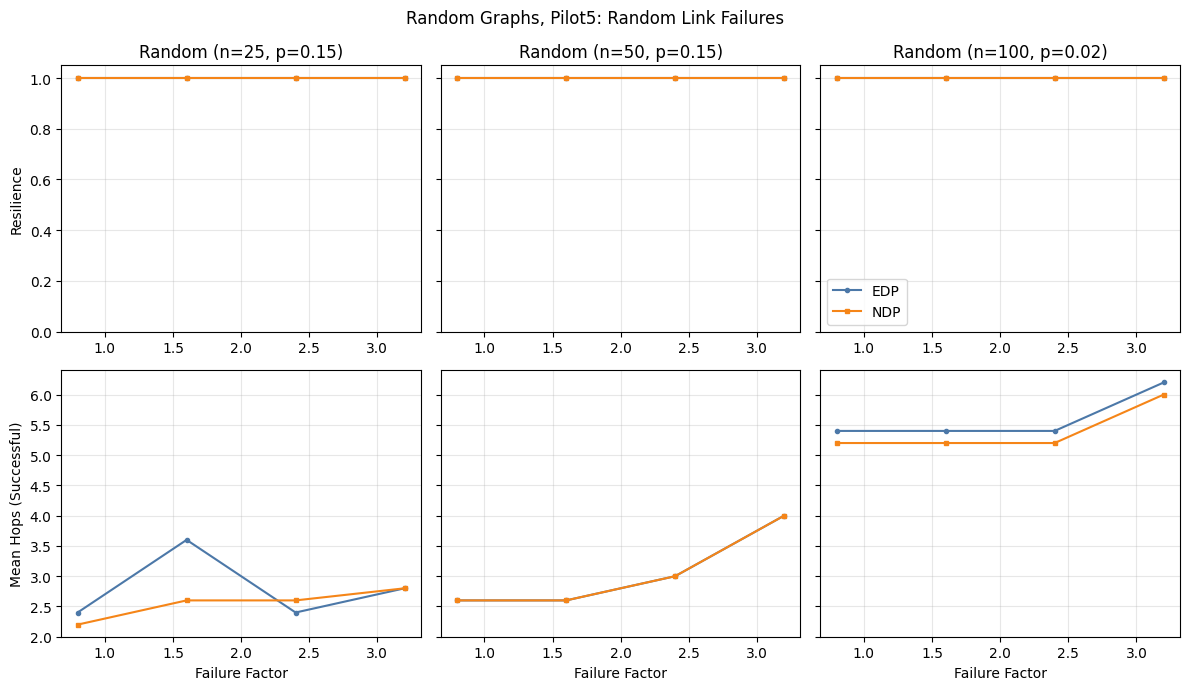

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_pilot5_random_link.png


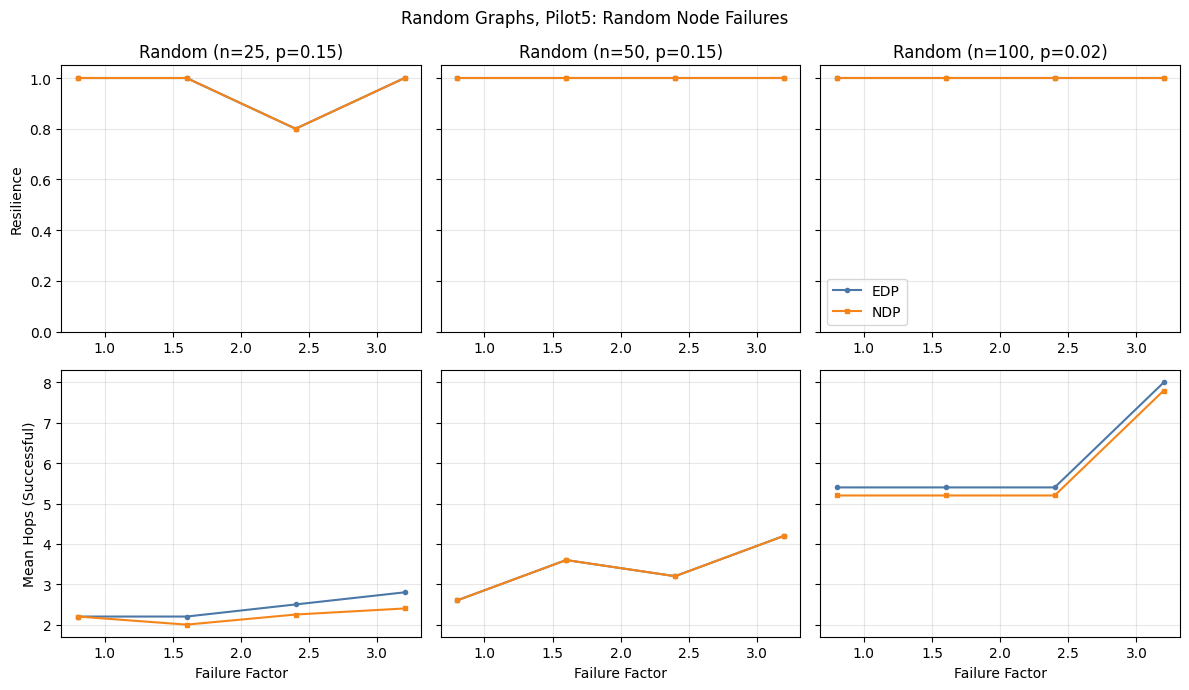

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_pilot5_random_node.png


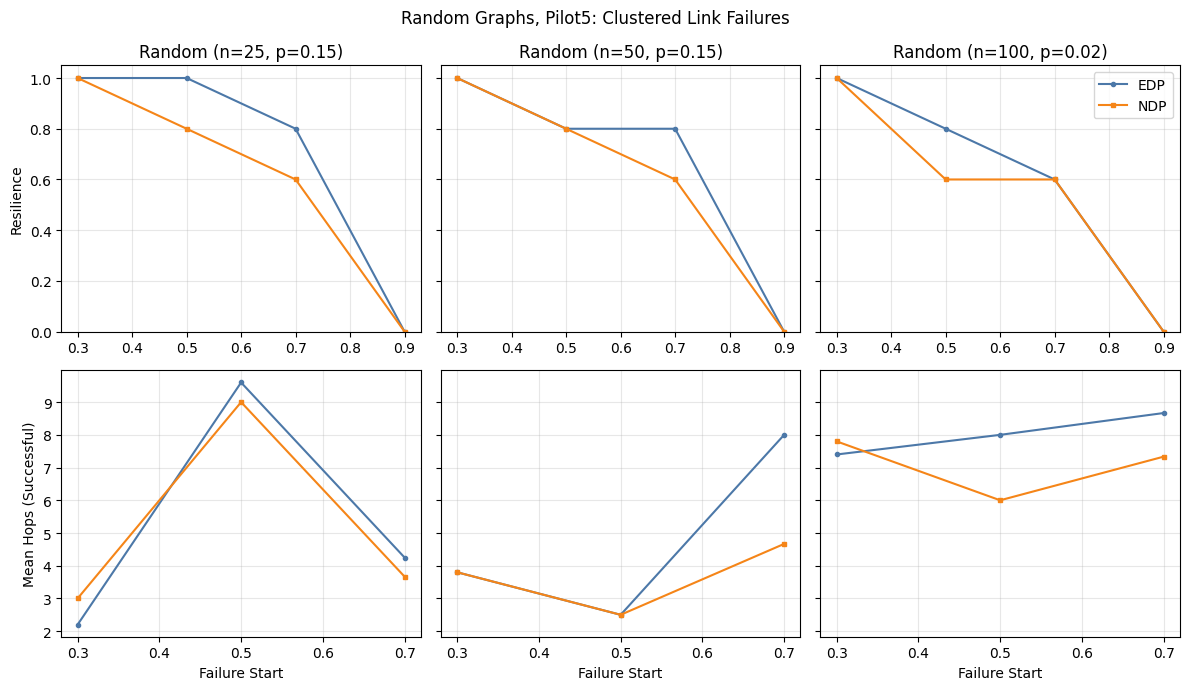

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_pilot5_clustered_link.png


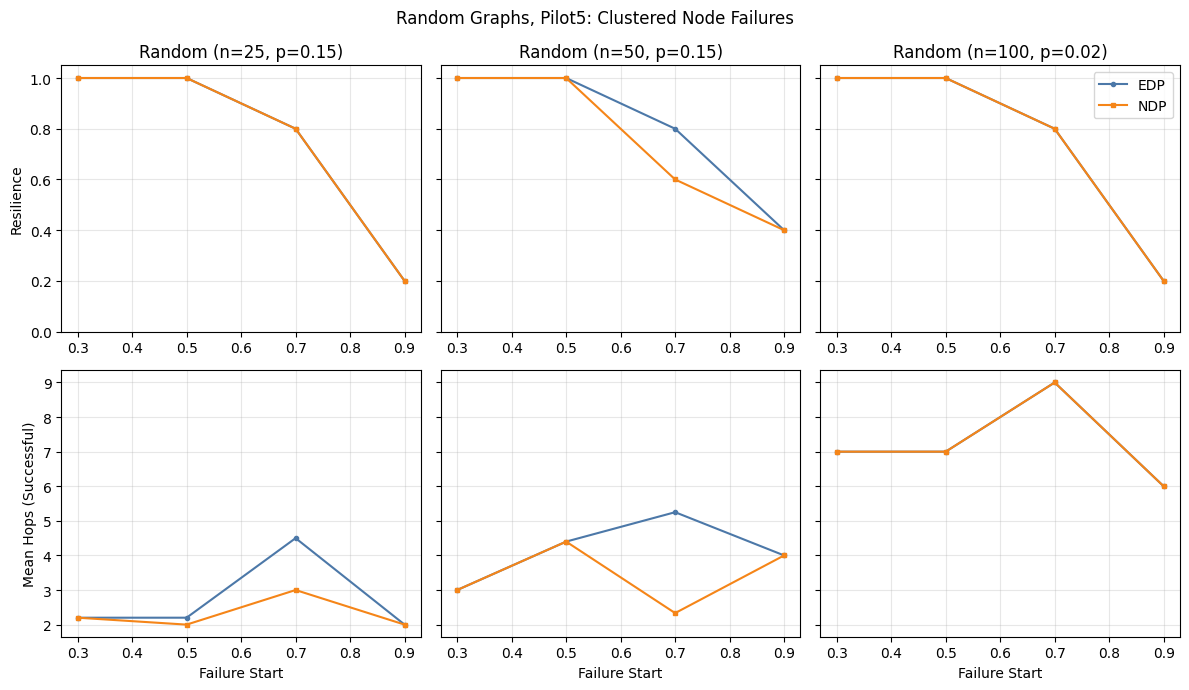

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_pilot5_clustered_node.png


Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_runs1000_random_link.png


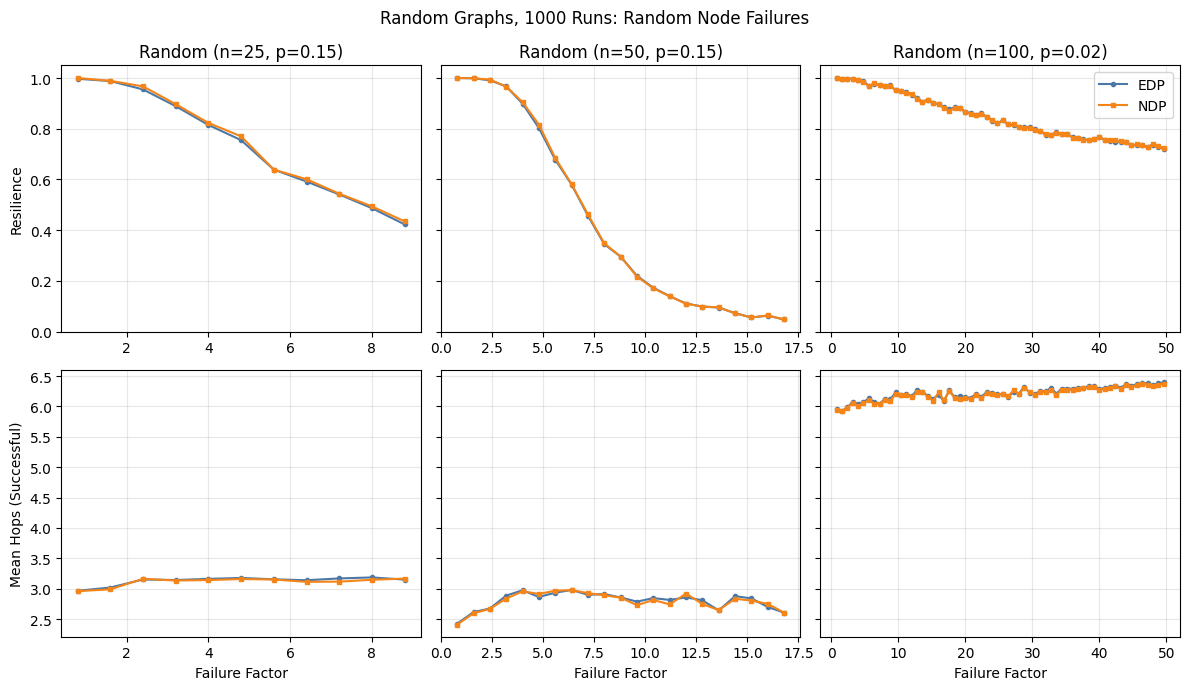

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_runs1000_random_node.png


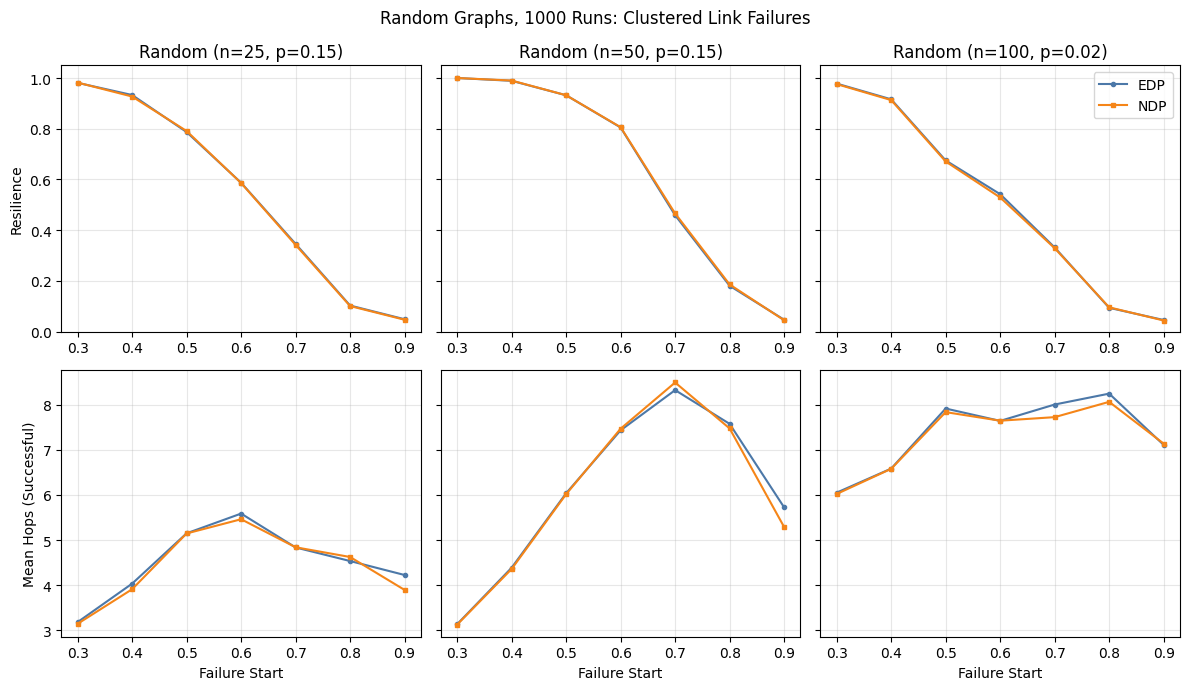

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_runs1000_clustered_link.png


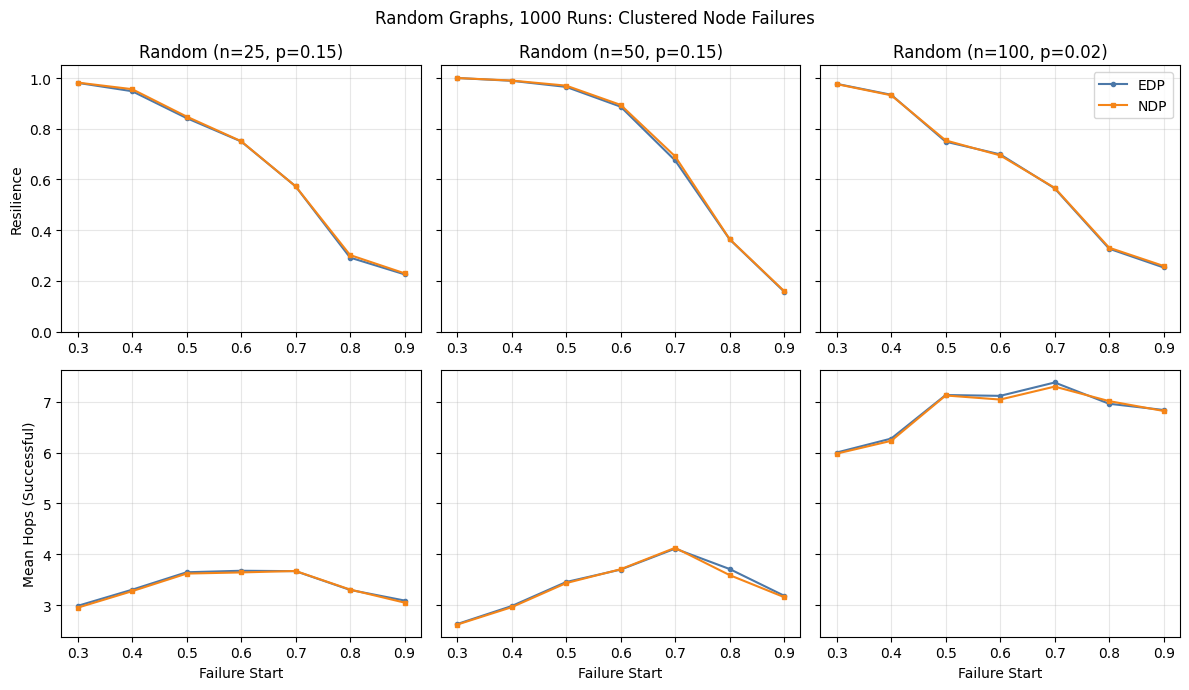

Plot: C:\Users\test\ba-gamous-disjoint\schritt3_knoten_disjunkte_pfade\evaluation\output\ndp_edp_random_runs1000\ndp_edp_random_runs1000_clustered_node.png


In [5]:
paper_summary = summarize(paper_raw, "graphKey")
paper_summary["series"] = None
paper_summary_rows = []
for series, frame in paper_raw.groupby("series"):
    part = summarize(frame, "graphKey")
    part["series"] = series
    paper_summary_rows.append(part)
paper_summary = pd.concat(paper_summary_rows, ignore_index=True)


def plot_random_grid(series, model, failure_type):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey="row")
    x_label = "Failure Factor" if model == "random" else "Failure Start"
    for column, graph in enumerate(RANDOM_GRAPHS):
        subset = paper_summary[
            (paper_summary["series"] == series)
            & (paper_summary["graphKey"] == graph["key"])
            & (paper_summary["failureModel"] == model)
            & (paper_summary["failureType"] == failure_type)
        ]
        for algorithm in ["EDP", "NDP"]:
            line = subset[subset["algorithm"] == algorithm]
            axes[0, column].plot(line["xValue"], line["resilience"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm, markersize=3)
            axes[1, column].plot(line["xValue"], line["meanHopsSuccessful"], marker=MARKERS[algorithm], color=COLORS[algorithm], label=algorithm, markersize=3)
        axes[0, column].set_title(graph["title"])
        axes[0, column].set_ylim(0, 1.05)
        axes[0, column].grid(alpha=0.3)
        axes[1, column].grid(alpha=0.3)
        axes[1, column].set_xlabel(x_label)
    axes[0, 0].set_ylabel("Resilience")
    axes[1, 0].set_ylabel("Mean Hops (Successful)")
    axes[0, 2].legend()
    series_title = "Pilot5" if series == "pilot5" else "1000 Runs"
    fig.suptitle(f"Random Graphs, {series_title}: {model.title()} {failure_type.title()} Failures")
    plt.tight_layout()
    output_path = PLOT_ROOT / f"ndp_edp_random_{series}_{model}_{failure_type}.png"
    plt.savefig(output_path, dpi=180)
    plt.show()
    print("Plot:", output_path)


for series in ["pilot5", "runs1000"]:
    for model in ["random", "clustered"]:
        for failure_type in ["link", "node"]:
            plot_random_grid(series, model, failure_type)


## Tatsächliche mittlere Ausfallzahlen und Resilience

In [6]:
paper_summary[
    ["series", "graphKey", "failureModel", "failureType", "xValue", "algorithm", "meanFailures", "resilience"]
].drop_duplicates(["series", "graphKey", "failureModel", "failureType", "xValue", "algorithm"])


,series,graphKey,failureModel,failureType,xValue,algorithm,meanFailures,resilience
0,pilot5,n100_p002,clustered,link,0.3,EDP,0.400,1.000
1,pilot5,n100_p002,clustered,link,0.3,NDP,0.400,1.000
2,pilot5,n100_p002,clustered,link,0.5,EDP,1.800,0.800
3,pilot5,n100_p002,clustered,link,0.5,NDP,1.800,0.600
4,pilot5,n100_p002,clustered,link,0.7,EDP,4.000,0.600
...,...,...,...,...,...,...,...,...
551,runs1000,n50_p015,random,node,15.2,NDP,44.936,0.056
552,runs1000,n50_p015,random,node,16.0,EDP,45.456,0.063
553,runs1000,n50_p015,random,node,16.0,NDP,45.456,0.064
554,runs1000,n50_p015,random,node,16.8,EDP,45.654,0.048
